In [1]:
import os
GPU_ID = os.environ.get("GPU_ID", "1")              # nvidia-smi index
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = GPU_ID

import sys, json, time, math, random, shutil, platform, pickle, contextlib, io, subprocess
import xml.etree.ElementTree as ET
from collections import Counter
from dataclasses import dataclass, field
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split

import torch

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "serve" / "app"))      # shared inference core
import pcb_core
from pcb_core import Detections, read_image, predict_full, predict_tiled, tile_origins, make_tiles, to_blob

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Python {platform.python_version()} | PyTorch {torch.__version__} | OpenCV {cv2.__version__}")
if DEVICE.type == "cuda":
    p = torch.cuda.get_device_properties(0)
    print(f"GPU (nvidia-smi index {GPU_ID}): {p.name} | CC {p.major}.{p.minor} | {p.total_memory / 2**30:.1f} GiB")
else:
    print("WARNING: no CUDA GPU visible; training will be very slow and TensorRT steps are skipped.")

import ultralytics
print("ultralytics", ultralytics.__version__)
try:
    import onnxruntime as ort
    if hasattr(ort, "preload_dlls"):
        with contextlib.suppress(Exception):
            ort.preload_dlls()
    ORT_PROVIDERS = ort.get_available_providers()
    print("onnxruntime", ort.__version__, ORT_PROVIDERS)
except ImportError:
    ort, ORT_PROVIDERS = None, []
HAS_ORT_CUDA = "CUDAExecutionProvider" in ORT_PROVIDERS and DEVICE.type == "cuda"
try:
    import modelopt
    HAS_MODELOPT = True
    print("modelopt", modelopt.__version__)
except ImportError:
    HAS_MODELOPT = False
    print("nvidia-modelopt not installed -> INT8/fp16 export (Step 8) will be skipped")
try:
    import tensorrt as trt
    HAS_TRT = DEVICE.type == "cuda"
    print("TensorRT", trt.__version__)
except ImportError:
    trt, HAS_TRT = None, False
    print("TensorRT not installed -> Steps 9-10 TensorRT parts skipped")

Python 3.10.11 | PyTorch 2.14.1+cu126 | OpenCV 5.0.0
GPU (nvidia-smi index 1): NVIDIA GeForce RTX 2080 Ti | CC 7.5 | 11.0 GiB
ultralytics 8.4.191
Skip loading CUDA and cuDNN DLLs since torch is imported.
onnxruntime 1.22.0 ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']
modelopt 0.47.0
TensorRT 11.4.0.106


In [2]:
CLASSES = list(pcb_core.CLASSES)

@dataclass
class Config:
    data_root: Path = Path(r"C:\Users\RTX2080Ti\Desktop\ex\PCB_defect\dataset")
    out_dir: Path = PROJECT_ROOT / "artifacts"
    model: str = os.environ.get("YOLO_MODEL", "yolo11s.pt")   # any Ultralytics detection checkpoint
    seed: int = 42
    split: tuple = (0.70, 0.15, 0.15)
    # tiling
    tile: int = 640
    overlap: float = 0.25            # 160 px overlap > largest defects, so every defect is whole in some tile
    tile_keep_ratio: float = 0.3     # keep a clipped box in a tile if >= 30 % of its area is inside
    neg_tile_ratio: float = 1.0      # background tiles per defect tile in the training set
    # training (per variant)
    variants: dict = field(default_factory=lambda: {
        "full640":  dict(mode="full",  imgsz=640,  epochs=100, batch=16, cache="disk"),
        "full1280": dict(mode="full",  imgsz=1280, epochs=100, batch=8,  cache="disk"),
        "tiled640": dict(mode="tiled", imgsz=640,  epochs=50,  batch=16, cache=False),
    })
    patience: int = 30
    workers: int = 4
    # inference / evaluation
    eval_conf: float = 0.001         # low threshold for mAP and for sweeping operating points
    nms_iou: float = 0.6
    merge_iou: float = 0.5
    edge_margin: int = 3
    match_iou: float = 0.25          # class-agnostic IoU for escape / false-call matching (tiny boxes!)
    fcpb_target: float = 0.2         # false-call budget: at most 1 false call per 5 boards (chosen on val)
    # export / benchmark
    calib_tiles: int = 256
    int8_keep_head_fp16: bool = True # keep the Detect head out of INT8 (box regression is sensitive)
    bench_boards: int = 60
    bench_warmup: int = 5

cfg = Config()
QUICK = os.environ.get("QUICK_RUN") == "1"        # tiny smoke-test settings
if QUICK:
    cfg.model = os.environ.get("YOLO_MODEL", "yolo11n.pt")
    for v in cfg.variants.values():
        v.update(epochs=1, batch=4)
    cfg.workers, cfg.calib_tiles, cfg.bench_boards, cfg.bench_warmup = 0, 8, 4, 1

assert cfg.data_root.exists(), f"PCB_ROOT not found: {cfg.data_root}"
for sub in ("datasets", "runs", "preds", "deploy", "engines", "results", "figures"):
    (cfg.out_dir / sub).mkdir(parents=True, exist_ok=True)
random.seed(cfg.seed); np.random.seed(cfg.seed); torch.manual_seed(cfg.seed)
print("Data:", cfg.data_root, "\nArtifacts:", cfg.out_dir, "\nModel:", cfg.model)

Data: C:\Users\RTX2080Ti\Desktop\ex\PCB_defect\dataset 
Artifacts: C:\Users\RTX2080Ti\Desktop\ex\PCB_defect\pcb-aoi_3\artifacts 
Model: yolo11s.pt


In [3]:
import yaml

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp"}

def norm_class(name):
    return str(name).strip().lower().replace(" ", "_").replace("-", "_")

# ---------- Format A: original PKU-Market-PCB (images/ + Annotations/*.xml + PCB_USED/) ----------
def parse_pku_xml(root):
    skip = lambda p: any(part.lower() in ("rotation", "pcb_used") for part in p.parts)
    images = {}
    for p in root.rglob("*"):
        if p.suffix.lower() in IMG_EXT and not skip(p.relative_to(root)):
            images[p.stem.lower()] = p
    records, problems = [], []
    for x in sorted(root.rglob("*.xml")):
        if skip(x.relative_to(root)):
            continue
        tree = ET.parse(x).getroot()
        img = images.get(x.stem.lower())
        if img is None:
            problems.append(f"no image for {x.name}"); continue
        boxes, labels = [], []
        for obj in tree.iter("object"):
            name = norm_class(obj.findtext("name"))
            if name not in CLASSES:
                problems.append(f"{x.name}: unknown class {name!r}"); continue
            bb = obj.find("bndbox")
            boxes.append([float(bb.findtext(k)) for k in ("xmin", "ymin", "xmax", "ymax")])
            labels.append(CLASSES.index(name))
        w, h = Image.open(img).size
        xw, xh = int(tree.findtext("size/width") or w), int(tree.findtext("size/height") or h)
        if (xw, xh) != (w, h):
            problems.append(f"{x.name}: xml size {xw}x{xh} != image {w}x{h}")
        b = np.array(boxes, np.float32).reshape(-1, 4)
        b[:, [0, 2]] = b[:, [0, 2]].clip(0, w); b[:, [1, 3]] = b[:, [1, 3]].clip(0, h)
        records.append({"stem": img.stem, "path": img, "w": w, "h": h, "split": None, "original": img.stem,
                        "board": img.stem.split("_")[0], "boxes": b, "labels": np.array(labels, np.int64),
                        "cls": Counter(labels).most_common(1)[0][0] if labels else -1})
    templates = sorted(p for p in root.rglob("*") if p.suffix.lower() in IMG_EXT and
                       any(part.lower() == "pcb_used" for part in p.relative_to(root).parts))
    return records, templates, problems, list(CLASSES)

# ---------- Format B: Roboflow YOLO export (train|valid|test/images + labels, data.yaml) ----------
def yolo_line_to_xyxy(parts, w, h):
    v = list(map(float, parts[1:]))
    if len(v) == 4:                                    # box: xc yc bw bh (normalised)
        xc, yc, bw, bh = v
        return [(xc - bw / 2) * w, (yc - bh / 2) * h, (xc + bw / 2) * w, (yc + bh / 2) * h]
    if len(v) >= 6 and len(v) % 2 == 0:                # polygon -> its bounding box
        xs, ys = np.array(v[0::2]) * w, np.array(v[1::2]) * h
        return [xs.min(), ys.min(), xs.max(), ys.max()]
    return None

def parse_roboflow(root):
    problems, records = [], []
    names = yaml.safe_load((root / "data.yaml").read_text())["names"]
    names = [names[k] for k in sorted(names)] if isinstance(names, dict) else list(names)
    classes = [norm_class(n) for n in names]
    for split, ours in (("train", "train"), ("valid", "val"), ("val", "val"), ("test", "test")):
        img_dir = root / split / "images"
        if not img_dir.is_dir():
            continue
        for img in sorted(img_dir.iterdir()):
            if img.suffix.lower() not in IMG_EXT:
                continue
            w, h = Image.open(img).size
            lbl = root / split / "labels" / f"{img.stem}.txt"
            boxes, labels = [], []
            for n, line in enumerate(lbl.read_text().splitlines() if lbl.exists() else [], 1):
                parts = line.split()
                if not parts:
                    continue
                b = yolo_line_to_xyxy(parts, w, h)
                c = int(float(parts[0]))
                if b is None or not 0 <= c < len(classes):
                    problems.append(f"{split}/{lbl.name}:{n} unreadable line"); continue
                b = [min(max(b[0], 0), w), min(max(b[1], 0), h), min(max(b[2], 0), w), min(max(b[3], 0), h)]
                if b[2] - b[0] >= 1 and b[3] - b[1] >= 1:
                    boxes.append(b); labels.append(c)
            original = img.name.split(".rf.")[0]       # Roboflow: <original>_jpg.rf.<hash>.jpg
            records.append({"stem": img.stem, "path": img, "w": w, "h": h, "split": ours, "original": original,
                            "board": original.split("_")[0], "boxes": np.array(boxes, np.float32).reshape(-1, 4),
                            "labels": np.array(labels, np.int64),
                            "cls": Counter(labels).most_common(1)[0][0] if labels else -1})
    return records, [], problems, classes

def describe_roboflow(root, records):
    for f in ("README.roboflow.txt", "README.dataset.txt"):
        if (root / f).exists():
            keys = ("resize", "stretch", "augment", "outputs per", "tile", "flip", "rotat", "crop", "process")
            lines = [l.strip() for l in (root / f).read_text(errors="ignore").splitlines()
                     if any(k in l.lower() for k in keys)]
            if lines:
                print(f"{f}:", *lines, sep="\n  ")
    for s in ("train", "val", "test"):
        rs = [r for r in records if r["split"] == s]
        if rs:
            sz = Counter((r["w"], r["h"]) for r in rs)
            n_orig = len({r["original"] for r in rs})
            print(f"{s}: {len(rs)} images from {n_orig} original boards; sizes (w,h): {dict(sz.most_common(3))}")

# ---------- detect the format and parse ----------
if (cfg.data_root / "data.yaml").exists():
    FORMAT = "roboflow"
    records, templates, problems, CLASSES = parse_roboflow(cfg.data_root)
    describe_roboflow(cfg.data_root, records)
else:
    FORMAT = "pku"
    records, templates, problems, CLASSES = parse_pku_xml(cfg.data_root)

print(f"\nformat: {FORMAT} | classes: {CLASSES}")
print(f"{len(records)} images, {sum(len(r['labels']) for r in records)} defects, "
      f"{sum(r['cls'] < 0 for r in records)} images without defects, {len(templates)} defect-free reference boards")
if problems:
    print(f"{len(problems)} problems, first 10:", *problems[:10], sep="\n  ")
assert records, "No annotated images found - PCB_ROOT must contain data.yaml (Roboflow) or images/ + Annotations/ (PKU)"

long_side = np.median([max(r["w"], r["h"]) for r in records])
if long_side <= 1024:
    print(f"\n!! WARNING: images are only ~{long_side:.0f} px on the long side. The original boards are ~3000 px.\n"
          "!! This export was resized, so defects are already shrunk and the tiling-vs-resolution comparison\n"
          "!! is not meaningful. Re-export without 'Resize', or use the original PKU-Market-PCB release.")

README.roboflow.txt:
  The following pre-processing was applied to each image:
  * Resize to 640x640 (Stretch)
  The following augmentation was applied to create 3 versions of each source image:
  * 50% probability of horizontal flip
  * 50% probability of vertical flip
  * Equal probability of one of the following 90-degree rotations: none, clockwise, counter-clockwise, upside-down
  * Random rotation of between -5 and +5 degrees
train: 2910 images from 625 original boards; sizes (w,h): {(640, 640): 2910}
val: 276 images from 244 original boards; sizes (w,h): {(640, 640): 276}
test: 140 images from 132 original boards; sizes (w,h): {(640, 640): 140}

format: roboflow | classes: ['missing_hole', 'mouse_bite', 'open_circuit', 'short', 'spur', 'spurious_copper']
3326 images, 13948 defects, 0 images without defects, 0 defect-free reference boards

!! WARNING: images are only ~640 px on the long side. The original boards are ~3000 px.
!! This export was resized, so defects are already shru

In [4]:
box_rows = []
for r in records:
    for b, l in zip(r["boxes"], r["labels"]):
        bw, bh = b[2] - b[0], b[3] - b[1]
        box_rows.append({"class": CLASSES[l], "w": bw, "h": bh, "area": bw * bh, "rel_w": bw / r["w"],
                         "board_area": r["w"] * r["h"]})
boxes_df = pd.DataFrame(box_rows)
boxes_df["coco_size"] = pd.cut(boxes_df.area, [0, 32**2, 96**2, np.inf], labels=["small", "medium", "large"])

per_class = boxes_df.groupby("class").agg(defects=("w", "size"), median_w_px=("w", "median"),
                                          median_h_px=("h", "median"), median_rel_width_pct=("rel_w", "median"))
per_class["median_rel_width_pct"] *= 100
per_class["images"] = pd.Series(Counter(CLASSES[r["cls"]] for r in records if r["cls"] >= 0))
size_tab = pd.crosstab(boxes_df["class"], boxes_df.coco_size, normalize="index").mul(100).round(1)
display(per_class.join(size_tab).round(2))

fg = boxes_df.area.sum() / sum(r["w"] * r["h"] for r in records)
sizes = Counter((r["w"], r["h"]) for r in records)
n_tiles = [len(tile_origins(r["h"], r["w"], cfg.tile, cfg.overlap)) for r in records]
MAX_TILES, TYPICAL_TILES = int(max(n_tiles)), int(np.median(n_tiles))
TYPICAL_HW = Counter((r["h"], r["w"]) for r in records).most_common(1)[0][0]
print(f"Board sizes (w x h): {dict(sizes.most_common(6))}")
print(f"Defect pixels cover {fg * 100:.3f} % of board area -> background outnumbers defects ~{1 / fg:,.0f}:1")
print(f"Median defect: {boxes_df.w.median():.0f} x {boxes_df.h.median():.0f} px = "
      f"{boxes_df.rel_w.median() * 100:.2f} % of board width; largest side max {max(boxes_df.w.max(), boxes_df.h.max()):.0f} px")
print(f"After resizing a board to 640 px the median defect is ~{boxes_df.w.median() * 640 / np.median([r['w'] for r in records]):.1f} px wide")
print(f"Tiles per board at {cfg.tile}px / {cfg.overlap:.0%} overlap: median {TYPICAL_TILES}, max {MAX_TILES}")

,defects,median_w_px,median_h_px,median_rel_width_pct,images,small,medium
class,,,,,,,
missing_hole,2315,17.0,19.0,2.66,536,98.4,1.6
mouse_bite,2358,16.0,18.5,2.50,564,100.0,0.0
open_circuit,2220,13.5,15.0,2.11,550,100.0,0.0
short,2341,21.5,23.0,3.36,562,90.2,9.8
spur,2327,19.0,20.0,2.97,560,97.6,2.4
spurious_copper,2387,20.0,21.5,3.12,554,97.8,2.2


Board sizes (w x h): {(640, 640): 3326}
Defect pixels cover 0.413 % of board area -> background outnumbers defects ~242:1
Median defect: 18 x 19 px = 2.73 % of board width; largest side max 71 px
After resizing a board to 640 px the median defect is ~17.5 px wide
Tiles per board at 640px / 25% overlap: median 1, max 1


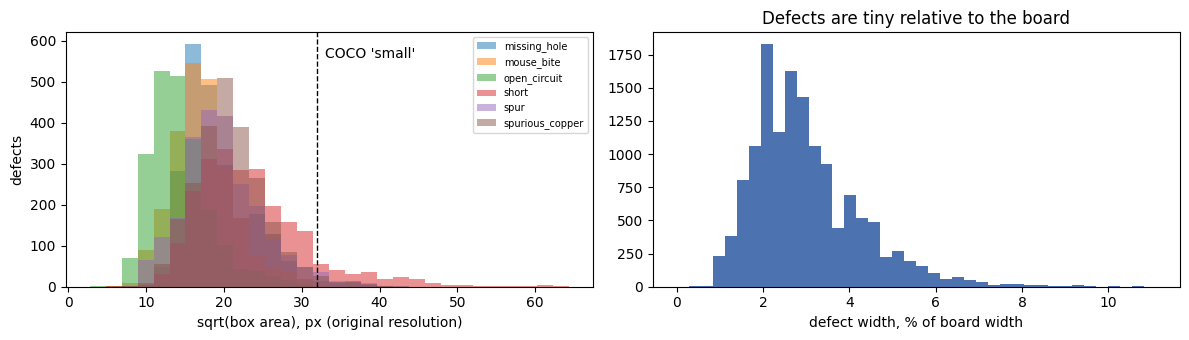

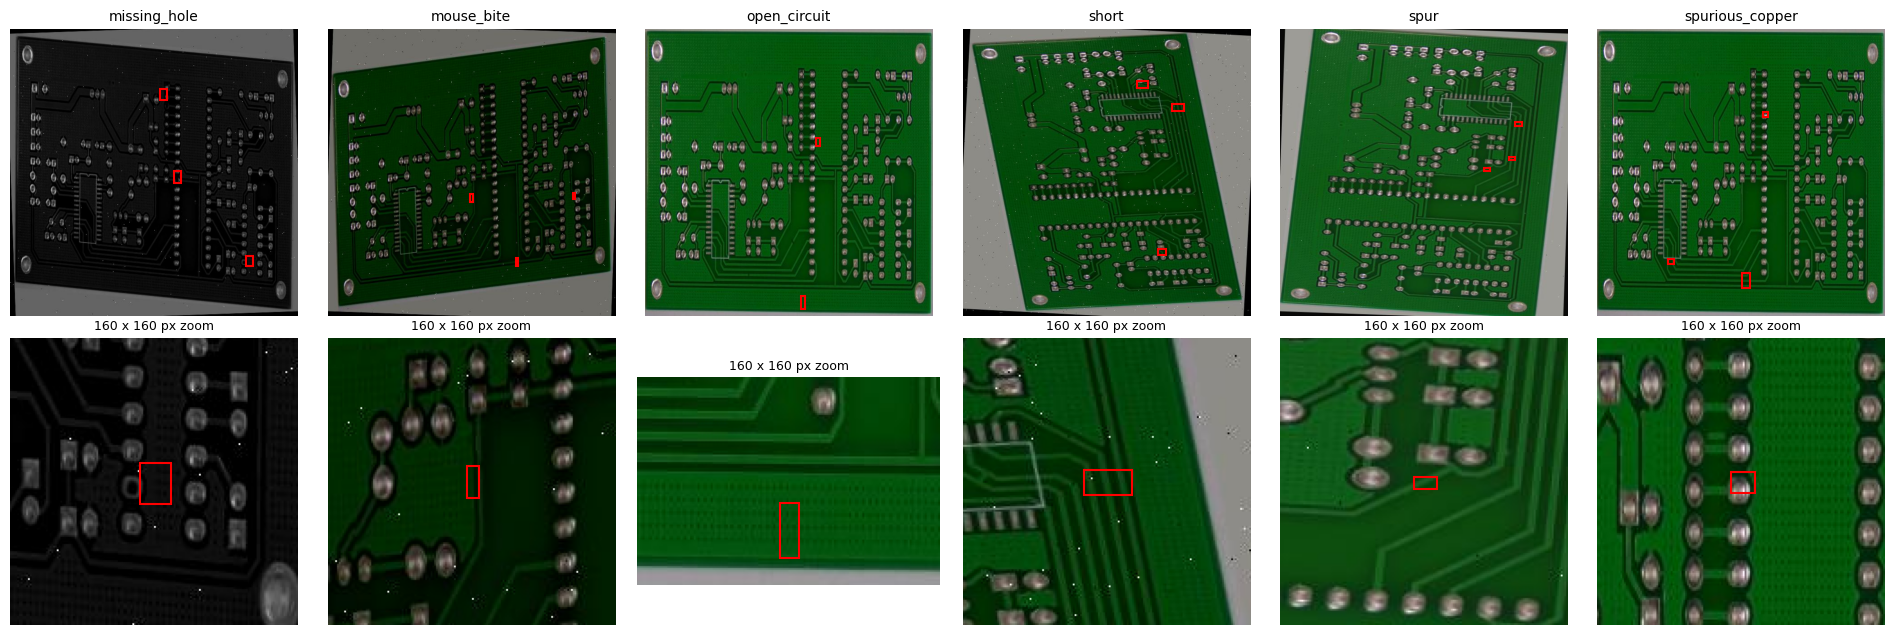

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
side = np.sqrt(boxes_df.area.astype(np.float64))
bins = np.linspace(side.min() - 1, side.max() + 1, 31)
for c in CLASSES:
    d = side[boxes_df["class"] == c]
    if len(d):
        axes[0].hist(d, bins=bins, alpha=0.5, label=c)
axes[0].axvline(32, color="k", ls="--", lw=1); axes[0].text(33, axes[0].get_ylim()[1] * 0.9, "COCO 'small'")
axes[0].set_xlabel("sqrt(box area), px (original resolution)"); axes[0].set_ylabel("defects"); axes[0].legend(fontsize=7)
axes[1].hist(boxes_df.rel_w.astype(np.float64) * 100, bins=np.linspace(0, boxes_df.rel_w.max() * 100 + 0.01, 41), color="#4C72B0")
axes[1].set_xlabel("defect width, % of board width"); axes[1].set_title("Defects are tiny relative to the board")
plt.tight_layout(); fig.savefig(cfg.out_dir / "figures" / "defect_sizes.png", dpi=150); plt.show()

# One example per class: full board + zoomed crop around a defect
fig, axes = plt.subplots(2, len(CLASSES), figsize=(3.2 * len(CLASSES), 6.4))
for j, c in enumerate(CLASSES):
    r = next(r for r in records if r["cls"] == j)
    img = read_image(r["path"])[..., ::-1]
    axes[0, j].imshow(img); axes[0, j].set_title(c, fontsize=10)
    for b in r["boxes"]:
        axes[0, j].add_patch(plt.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, ec="red", lw=1.5))
    b = r["boxes"][0].astype(int); cx, cy = (b[0] + b[2]) // 2, (b[1] + b[3]) // 2; s = 80
    crop = img[max(cy - s, 0):cy + s, max(cx - s, 0):cx + s]
    axes[1, j].imshow(crop); axes[1, j].add_patch(plt.Rectangle((b[0] - max(cx - s, 0), b[1] - max(cy - s, 0)),
                                                               b[2] - b[0], b[3] - b[1], fill=False, ec="red", lw=1.5))
    axes[1, j].set_title("160 x 160 px zoom", fontsize=9)
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); fig.savefig(cfg.out_dir / "figures" / "examples.png", dpi=150); plt.show()

In [6]:
if FORMAT == "roboflow":
    # This export's own split puts copies of the same board into train AND valid/test (leakage),
    # so we ignore it and re-split by ORIGINAL board: all copies of one board go to the same split.
    groups = {}
    for r in records:
        groups.setdefault(r["original"], []).append(r)
    keys = sorted(groups)
    gcls = [Counter(int(r["cls"]) for r in groups[k]).most_common(1)[0][0] for k in keys]
    n_cross = sum(len({r["split"] for r in groups[k]}) > 1 for k in keys)
    print(f"{len(records)} images = {len(keys)} original boards "
          f"(copies per board: {dict(Counter(len(v) for v in groups.values()))}); "
          f"{n_cross} boards were spread over several splits in the export")

    gidx = np.arange(len(keys))
    tr, tmp = train_test_split(gidx, test_size=1 - cfg.split[0], stratify=gcls, random_state=cfg.seed)
    try:
        va, te = train_test_split(tmp, test_size=cfg.split[2] / (cfg.split[1] + cfg.split[2]),
                                  stratify=[gcls[i] for i in tmp], random_state=cfg.seed)
    except ValueError:      # only with very small datasets
        va, te = train_test_split(tmp, test_size=cfg.split[2] / (cfg.split[1] + cfg.split[2]), random_state=cfg.seed)

    one_per_board = lambda k: sorted(groups[k], key=lambda r: r["stem"])[0]
    SPLITS = {"train": [r for i in tr for r in groups[keys[i]]],      # all copies = extra augmentation
              "val": [one_per_board(keys[i]) for i in va],            # one image per board for evaluation
              "test": [one_per_board(keys[i]) for i in te]}
    for s, v in SPLITS.items():
        for r in v:
            r["split"] = s

    # Sanity check: no board in more than one split now
    orig = {s: {r["original"] for r in v} for s, v in SPLITS.items()}
    assert not ((orig["train"] & orig["val"]) | (orig["train"] & orig["test"]) | (orig["val"] & orig["test"]))
    print({s: f"{len(v)} images / {len(orig[s])} boards" for s, v in SPLITS.items()})
else:
    idx = np.arange(len(records)); strat = [r["cls"] for r in records]
    tr, tmp = train_test_split(idx, test_size=1 - cfg.split[0], stratify=strat, random_state=cfg.seed)
    try:
        va, te = train_test_split(tmp, test_size=cfg.split[2] / (cfg.split[1] + cfg.split[2]),
                                  stratify=[strat[i] for i in tmp], random_state=cfg.seed)
    except ValueError:      # only happens with very small datasets
        va, te = train_test_split(tmp, test_size=cfg.split[2] / (cfg.split[1] + cfg.split[2]), random_state=cfg.seed)
    SPLITS = {"train": [records[i] for i in tr], "val": [records[i] for i in va], "test": [records[i] for i in te]}

(cfg.out_dir / "results" / "split.json").write_text(json.dumps({k: [r["stem"] for r in v] for k, v in SPLITS.items()}, indent=1))
pd.DataFrame({k: Counter(CLASSES[r["cls"]] if r["cls"] >= 0 else "(no defect)" for r in v)
              for k, v in SPLITS.items()}).fillna(0).astype(int).assign(total=lambda d: d.sum(1))

3326 images = 693 original boards (copies per board: {6: 345, 4: 280, 2: 68}); 308 boards were spread over several splits in the export
{'train': '2340 images / 485 boards', 'val': '104 images / 104 boards', 'test': '104 images / 104 boards'}


,train,val,test,total
spur,394,17,18,429
open_circuit,394,17,18,429
short,396,18,17,431
mouse_bite,398,17,17,432
spurious_copper,388,18,17,423
missing_hole,370,17,17,404


In [7]:
def link_or_copy(src, dst):
    dst.parent.mkdir(parents=True, exist_ok=True)
    if dst.exists():
        return
    try:
        os.link(src, dst)
    except OSError:
        shutil.copy2(src, dst)

def write_labels(path, boxes, labels, w, h):
    path.parent.mkdir(parents=True, exist_ok=True)
    lines = []
    for (x1, y1, x2, y2), c in zip(boxes, labels):
        lines.append(f"{c} {(x1 + x2) / 2 / w:.6f} {(y1 + y2) / 2 / h:.6f} {(x2 - x1) / w:.6f} {(y2 - y1) / h:.6f}")
    path.write_text("\n".join(lines))

def write_yaml(root, path):
    path.write_text("\n".join([f"path: {root.as_posix()}", "train: images/train", "val: images/val", "test: images/test",
                               "names:"] + [f"  {i}: {c}" for i, c in enumerate(CLASSES)]))
    return path

def build_full_dataset():
    root = cfg.out_dir / "datasets" / "full"
    for split, recs in SPLITS.items():
        for r in recs:
            link_or_copy(r["path"], root / "images" / split / r["path"].name)
            write_labels(root / "labels" / split / f"{r['path'].stem}.txt", r["boxes"], r["labels"], r["w"], r["h"])
    return write_yaml(root, root / "data.yaml")

def tile_boxes(boxes, labels, x0, y0, t):
    if len(boxes) == 0:
        return boxes, labels
    c = boxes - np.array([x0, y0, x0, y0], np.float32)
    clipped = c.copy(); clipped[:, [0, 2]] = clipped[:, [0, 2]].clip(0, t); clipped[:, [1, 3]] = clipped[:, [1, 3]].clip(0, t)
    area = (c[:, 2] - c[:, 0]) * (c[:, 3] - c[:, 1])
    carea = (clipped[:, 2] - clipped[:, 0]).clip(0) * (clipped[:, 3] - clipped[:, 1]).clip(0)
    keep = (carea >= cfg.tile_keep_ratio * area) & ((clipped[:, 2] - clipped[:, 0]) >= 2) & ((clipped[:, 3] - clipped[:, 1]) >= 2)
    return clipped[keep], labels[keep]

def build_tile_dataset():
    root = cfg.out_dir / "datasets" / "tiles"
    marker = root / "DONE"
    if marker.exists():
        return root / "data.yaml"
    rng = np.random.default_rng(cfg.seed)
    stats = Counter()
    for split in ("train", "val"):
        for r in tqdm(SPLITS[split], desc=f"tiling {split}"):
            img = read_image(r["path"])
            tiles, origins = make_tiles(img, cfg.tile, cfg.overlap)
            pos, neg = [], []
            for k, (x0, y0) in enumerate(origins.astype(int)):
                b, l = tile_boxes(r["boxes"], r["labels"], x0, y0, cfg.tile)
                (pos if len(l) else neg).append((k, x0, y0, b, l))
            n_neg = min(len(neg), int(math.ceil(cfg.neg_tile_ratio * max(len(pos), 1))))
            chosen = pos + [neg[i] for i in rng.choice(len(neg), n_neg, replace=False)] if neg else pos
            for k, x0, y0, b, l in chosen:
                name = f"{r['stem']}_{x0}_{y0}"
                ok, buf = cv2.imencode(".jpg", tiles[k], [cv2.IMWRITE_JPEG_QUALITY, 95])
                dst = root / "images" / split / f"{name}.jpg"; dst.parent.mkdir(parents=True, exist_ok=True)
                buf.tofile(str(dst))
                write_labels(root / "labels" / split / f"{name}.txt", b, l, cfg.tile, cfg.tile)
            stats[f"{split}_pos"] += len(pos); stats[f"{split}_neg_kept"] += n_neg; stats[f"{split}_neg_total"] += len(neg)
    (root / "images" / "test").mkdir(parents=True, exist_ok=True)   # test is evaluated on full boards
    (root / "labels" / "test").mkdir(parents=True, exist_ok=True)
    marker.write_text(json.dumps(stats))
    return write_yaml(root, root / "data.yaml")

DATA_YAML = {"full": build_full_dataset(), "tiled": build_tile_dataset()}
print(json.loads((cfg.out_dir / "datasets" / "tiles" / "DONE").read_text()))

{'train_pos': 2340, 'train_neg_kept': 0, 'train_neg_total': 0, 'val_pos': 104, 'val_neg_kept': 0, 'val_neg_total': 0}


In [8]:
from ultralytics import YOLO

def train_variant(name, v):
    run_dir = cfg.out_dir / "runs" / name
    done, last = run_dir / "DONE", run_dir / "weights" / "last.pt"
    if done.exists():
        print(f"{name}: already trained -> {run_dir / 'weights' / 'best.pt'}")
        return run_dir / "weights" / "best.pt"
    t0 = time.perf_counter()
    if last.exists():
        print(f"{name}: resuming from {last}")
        model = YOLO(str(last)); model.train(resume=True)
    else:
        model = YOLO(cfg.model)
        model.train(data=str(DATA_YAML[v["mode"]]), imgsz=v["imgsz"], epochs=v["epochs"], batch=v["batch"],
                    patience=cfg.patience, device=0 if DEVICE.type == "cuda" else "cpu", workers=cfg.workers,
                    cache=v["cache"], seed=cfg.seed, project=str(cfg.out_dir / "runs"), name=name, exist_ok=True,
                    fliplr=0.5, flipud=0.5, close_mosaic=10, amp=DEVICE.type == "cuda", plots=True, verbose=False)
    best = Path(model.trainer.best)
    done.write_text(json.dumps({"best": str(best), "train_minutes": (time.perf_counter() - t0) / 60}))
    return best

WEIGHTS = {}
for name, v in cfg.variants.items():
    WEIGHTS[name] = train_variant(name, v)
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
WEIGHTS

full640: already trained -> C:\Users\RTX2080Ti\Desktop\ex\PCB_defect\pcb-aoi_3\artifacts\runs\full640\weights\best.pt
full1280: already trained -> C:\Users\RTX2080Ti\Desktop\ex\PCB_defect\pcb-aoi_3\artifacts\runs\full1280\weights\best.pt
tiled640: already trained -> C:\Users\RTX2080Ti\Desktop\ex\PCB_defect\pcb-aoi_3\artifacts\runs\tiled640\weights\best.pt


{'full640': WindowsPath('C:/Users/RTX2080Ti/Desktop/ex/PCB_defect/pcb-aoi_3/artifacts/runs/full640/weights/best.pt'),
 'full1280': WindowsPath('C:/Users/RTX2080Ti/Desktop/ex/PCB_defect/pcb-aoi_3/artifacts/runs/full1280/weights/best.pt'),
 'tiled640': WindowsPath('C:/Users/RTX2080Ti/Desktop/ex/PCB_defect/pcb-aoi_3/artifacts/runs/tiled640/weights/best.pt')}

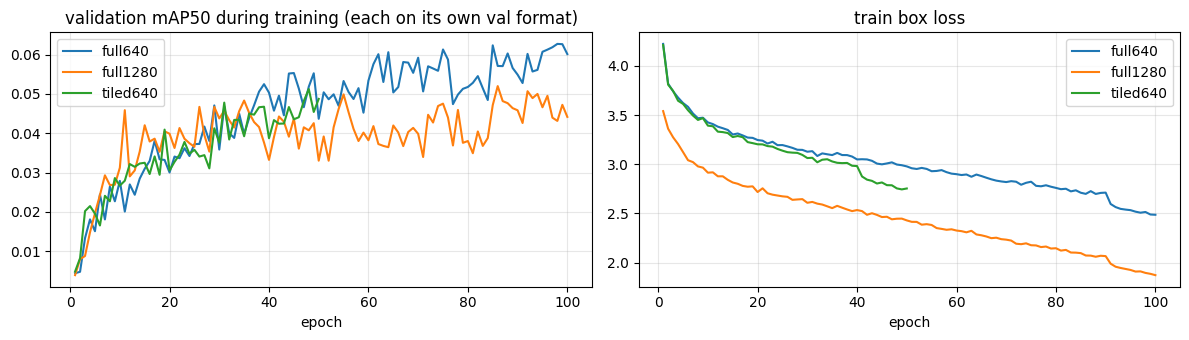

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for name in cfg.variants:
    f = cfg.out_dir / "runs" / name / "results.csv"
    if f.exists():
        d = pd.read_csv(f); d.columns = [c.strip() for c in d.columns]
        axes[0].plot(d["epoch"], d["metrics/mAP50(B)"], label=name)
        axes[1].plot(d["epoch"], d["train/box_loss"], label=name)
axes[0].set_title("validation mAP50 during training (each on its own val format)"); axes[1].set_title("train box loss")
for a in axes: a.legend(); a.set_xlabel("epoch"); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [10]:
class TorchRunner:
    # Ultralytics nn.Module as a pcb_core RunFn: float32 NCHW numpy -> raw head output numpy.
    def __init__(self, weights, half=False):
        m = YOLO(str(weights)).model
        m = m.fuse(verbose=False) if hasattr(m, "fuse") else m
        self.half = half and DEVICE.type == "cuda"
        self.m = (m.half() if self.half else m.float()).to(DEVICE).eval()
    @torch.inference_mode()
    def __call__(self, blob):
        x = torch.from_numpy(blob).to(DEVICE, non_blocking=True)
        y = self.m(x.half() if self.half else x)
        y = y[0] if isinstance(y, (list, tuple)) else y
        return y.float().cpu().numpy()

def infer_boards(run, recs, v, conf, progress=None):
    preds, times = [], []
    sync = torch.cuda.synchronize if DEVICE.type == "cuda" else (lambda: None)
    for r in tqdm(recs, desc=progress, leave=False, disable=progress is None):
        t0 = time.perf_counter()
        img = read_image(r["path"] if isinstance(r, dict) else r)
        t1 = time.perf_counter(); tm = {}
        if v["mode"] == "tiled":
            det = predict_tiled(run, img, cfg.tile, cfg.overlap, conf, cfg.nms_iou, cfg.merge_iou,
                                cfg.edge_margin, max_batch=MAX_TILES, timings=tm)
        else:
            det = predict_full(run, img, v["imgsz"], conf, cfg.nms_iou)
        sync(); t2 = time.perf_counter()
        preds.append(det); times.append({"decode_ms": (t1 - t0) * 1e3, "board_ms": (t2 - t0) * 1e3, **tm})
    return preds, times

In [11]:
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

def coco_eval(recs, preds):
    gt = {"images": [], "annotations": [], "categories": [{"id": i + 1, "name": c} for i, c in enumerate(CLASSES)]}
    dets, aid = [], 1
    for i, (r, d) in enumerate(zip(recs, preds)):
        gt["images"].append({"id": i, "width": r["w"], "height": r["h"]})
        for b, l in zip(r["boxes"], r["labels"]):
            w, h = float(b[2] - b[0]), float(b[3] - b[1])
            gt["annotations"].append({"id": aid, "image_id": i, "category_id": int(l) + 1, "bbox": [float(b[0]), float(b[1]), w, h],
                                      "area": w * h, "iscrowd": 0}); aid += 1
        for b, s, c in zip(d.boxes, d.scores, d.classes):
            dets.append({"image_id": i, "category_id": int(c) + 1, "score": float(s),
                         "bbox": [float(b[0]), float(b[1]), float(b[2] - b[0]), float(b[3] - b[1])]})
    with contextlib.redirect_stdout(io.StringIO()):
        coco = COCO(); coco.dataset = gt; coco.createIndex()
        if not dets:
            return {"mAP50-95": 0.0, "mAP50": 0.0, "AP_small": 0.0, "AP_medium": 0.0}, {c: (0.0, 0.0) for c in CLASSES}
        E = COCOeval(coco, coco.loadRes(dets), "bbox"); E.evaluate(); E.accumulate(); E.summarize()
    s = E.stats
    fix = lambda x: float("nan") if x < 0 else float(x)            # -1 = no objects of that size
    overall = {"mAP50-95": fix(s[0]), "mAP50": fix(s[1]), "AP_small": fix(s[3]), "AP_medium": fix(s[4])}
    P = E.eval["precision"]                         # [T, R, K, A, M]
    per_class = {}
    for k, c in enumerate(CLASSES):
        p = P[:, :, k, 0, -1]
        ap = p[p > -1].mean() if (p > -1).any() else float("nan")
        p50 = P[0, :, k, 0, -1]
        per_class[c] = (p50[p50 > -1].mean() if (p50 > -1).any() else float("nan"), ap)
    return overall, per_class


def box_iou(a, b):
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)), np.float32)
    lt = np.maximum(a[:, None, :2], b[None, :, :2]); rb = np.minimum(a[:, None, 2:], b[None, :, 2:])
    inter = (rb - lt).clip(0).prod(2)
    area = lambda x: (x[:, 2] - x[:, 0]) * (x[:, 3] - x[:, 1])
    return inter / (area(a)[:, None] + area(b)[None] - inter + 1e-9)

def aoi_scores(recs, preds, iou_thr):
    # per GT: best score of any overlapping detection (0 if none); per detection: score if it is a false call
    gt_best, fp_scores = [], []
    for r, d in zip(recs, preds):
        M = box_iou(r["boxes"], d.boxes) >= iou_thr
        if len(r["boxes"]):
            gt_best.append((M * d.scores[None]).max(1) if len(d) else np.zeros(len(r["boxes"])))
        fp_scores.append(d.scores[~M.any(0)] if len(d) else np.zeros(0))
    return np.concatenate(gt_best) if gt_best else np.zeros(0), np.concatenate(fp_scores), len(recs)

def froc_curve(gt_best, fp_scores, n_boards):
    thr = np.unique(np.concatenate([gt_best[gt_best > 0], fp_scores, [1.0 + 1e-6]]))
    gs, fs = np.sort(gt_best), np.sort(fp_scores)
    escape = np.searchsorted(gs, thr, side="left") / max(len(gs), 1)              # fraction with best < thr
    fcpb = (len(fs) - np.searchsorted(fs, thr, side="left")) / n_boards           # false calls >= thr per board
    return thr, escape, fcpb

def threshold_for_fcpb(gt_best, fp_scores, n_boards, target):
    thr, esc, fc = froc_curve(gt_best, fp_scores, n_boards)
    ok = np.where(fc <= target)[0]
    return float(thr[ok[0]]) if len(ok) else 1.0

def at_threshold(gt_best, fp_scores, n_boards, t):
    return {"escape_rate": float(np.mean(gt_best < t)) if len(gt_best) else float("nan"),
            "false_calls_per_board": float(np.sum(fp_scores >= t) / n_boards)}

In [12]:
PRED_DIR = cfg.out_dir / "preds"

def cached_inference(name, split, run_factory, recs, v):
    f = PRED_DIR / f"{name}_{split}.pkl"
    if f.exists():
        return pickle.loads(f.read_bytes())
    preds, times = infer_boards(run_factory(), recs, v, cfg.eval_conf, progress=f"{name}/{split}")
    f.write_bytes(pickle.dumps((preds, times)))
    return preds, times

results, curves, per_class_ap, OPS = [], {}, {}, {}
for name, v in cfg.variants.items():
    runner = TorchRunner(WEIGHTS[name])
    factory = lambda r=runner: r
    vp, _ = cached_inference(name, "val", factory, SPLITS["val"], v)
    tp, tt = cached_inference(name, "test", factory, SPLITS["test"], v)
    gp, _ = cached_inference(name, "good", factory, templates, v) if templates else ([], [])
    # operating point on validation
    val_overall, _ = coco_eval(SPLITS["val"], vp)
    t_op = threshold_for_fcpb(*aoi_scores(SPLITS["val"], vp, cfg.match_iou), cfg.fcpb_target)
    val_op = at_threshold(*aoi_scores(SPLITS["val"], vp, cfg.match_iou), t_op)
    gt_best, fp_s, nb = aoi_scores(SPLITS["test"], tp, cfg.match_iou)
    curves[name] = froc_curve(gt_best, fp_s, nb)
    overall, pc = coco_eval(SPLITS["test"], tp)
    per_class_ap[name] = pc
    test_op = at_threshold(gt_best, fp_s, nb, t_op)
    good = {}
    if templates:
        flagged = [int((d.scores >= t_op).sum()) for d in gp]
        good = {"good_boards_flagged_pct": 100 * np.mean([f > 0 for f in flagged]),
                "false_calls_per_good_board": float(np.mean(flagged))}
    bt = np.array([t["board_ms"] for t in tt])
    OPS[name] = t_op
    results.append({"variant": name, **{k: 100 * x for k, x in overall.items()},
                    "conf_threshold": t_op, "val_mAP50": 100 * val_overall["mAP50"], "val_escape_pct": 100 * val_op["escape_rate"],
                    "test_escape_pct": 100 * test_op["escape_rate"], "test_false_calls_per_board": test_op["false_calls_per_board"],
                    **good, "board_ms_p50": np.percentile(bt, 50), "board_ms_p95": np.percentile(bt, 95)})
    del runner
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

res_df = pd.DataFrame(results).set_index("variant")
res_df.to_csv(cfg.out_dir / "results" / "variant_comparison.csv")
# Chosen on VALIDATION, not test: lowest escape rate at the false-call budget, ties broken by validation mAP50
BEST = res_df.sort_values(["val_escape_pct", "val_mAP50"], ascending=[True, False]).index[0]
print(f"Deployed variant (lowest validation escape rate at {cfg.fcpb_target} false calls/board): {BEST}")
res_df.round(3)

Deployed variant (lowest validation escape rate at 0.2 false calls/board): full640


,mAP50-95,mAP50,AP_small,AP_medium,conf_threshold,val_mAP50,val_escape_pct,test_escape_pct,test_false_calls_per_board,board_ms_p50,board_ms_p95
variant,,,,,,,,,,,
full640,1.646,5.584,1.673,0.000,0.144,6.623,96.110,96.575,0.288,22.322,26.437
full1280,1.259,4.150,1.270,1.141,0.213,5.223,96.339,97.717,0.558,42.074,47.670
tiled640,1.551,5.022,1.580,0.000,0.108,5.844,96.339,96.804,0.173,21.735,26.215


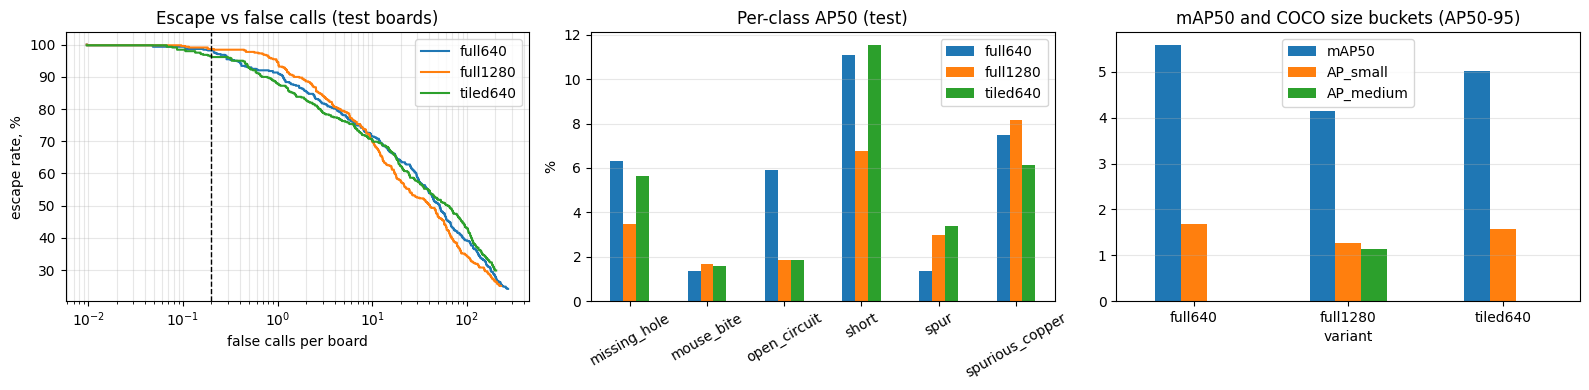

,full640,full1280,tiled640
AP50 / AP50-95,,,
missing_hole,6.3 / 1.9,3.5 / 1.0,5.6 / 1.8
mouse_bite,1.4 / 0.4,1.7 / 0.6,1.6 / 0.5
open_circuit,5.9 / 1.3,1.9 / 0.5,1.8 / 0.6
short,11.1 / 3.7,6.8 / 2.3,11.5 / 3.2
spur,1.3 / 0.4,3.0 / 0.7,3.4 / 1.5
spurious_copper,7.5 / 2.1,8.2 / 2.5,6.1 / 1.8


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for name, (thr, esc, fc) in curves.items():
    m = fc > 0
    axes[0].plot(fc[m], 100 * esc[m], label=name)
axes[0].axvline(cfg.fcpb_target, color="k", ls="--", lw=1)
axes[0].set_xscale("log"); axes[0].set_xlabel("false calls per board"); axes[0].set_ylabel("escape rate, %")
axes[0].set_title("Escape vs false calls (test boards)"); axes[0].grid(alpha=0.3, which="both"); axes[0].legend()

pc = pd.DataFrame({n: {c: v[0] * 100 for c, v in d.items()} for n, d in per_class_ap.items()})
pc.plot.bar(ax=axes[1]); axes[1].set_title("Per-class AP50 (test)"); axes[1].set_ylabel("%")
axes[1].tick_params(axis="x", rotation=30)
res_df[["mAP50", "AP_small", "AP_medium"]].plot.bar(ax=axes[2]); axes[2].set_title("mAP50 and COCO size buckets (AP50-95)")
axes[2].tick_params(axis="x", rotation=0)
for a in axes[1:]: a.grid(axis="y", alpha=0.3)
plt.tight_layout(); fig.savefig(cfg.out_dir / "figures" / "variant_comparison.png", dpi=150); plt.show()
pd.DataFrame({n: {c: f"{v[0]*100:.1f} / {v[1]*100:.1f}" for c, v in d.items()} for n, d in per_class_ap.items()}).rename_axis("AP50 / AP50-95")

In [14]:
def confusion_at(recs, preds, t, iou_thr):
    # rows: true class (+ 'false call'); columns: predicted class (+ 'escaped')
    labels = CLASSES + ["escaped"]
    cm = pd.DataFrame(0, index=CLASSES + ["false call"], columns=labels)
    for r, d in zip(recs, preds):
        d = d.filter(d.scores >= t)
        M = box_iou(r["boxes"], d.boxes) >= iou_thr
        for g, l in enumerate(r["labels"]):
            hits = np.where(M[g])[0] if len(d) else []
            col = CLASSES[int(d.classes[hits[np.argmax(d.scores[hits])]])] if len(hits) else "escaped"
            cm.loc[CLASSES[l], col] += 1
        for k in (np.where(~M.any(0))[0] if len(d) else []):
            cm.loc["false call", CLASSES[int(d.classes[k])]] += 1
    return cm

tp_best, _ = pickle.loads((PRED_DIR / f"{BEST}_test.pkl").read_bytes())
cm = confusion_at(SPLITS["test"], tp_best, OPS[BEST], cfg.match_iou)
print(f"{BEST} @ conf {OPS[BEST]:.3f} (test): rows = ground truth, columns = prediction")
cm

full640 @ conf 0.144 (test): rows = ground truth, columns = prediction


,missing_hole,mouse_bite,open_circuit,short,spur,spurious_copper,escaped
missing_hole,0,0,0,0,0,0,78
mouse_bite,0,1,0,0,0,0,70
open_circuit,0,0,1,0,0,0,74
short,0,0,0,5,0,0,70
spur,0,0,0,0,4,0,66
spurious_copper,0,0,0,0,0,4,65
false call,0,10,1,4,7,8,0


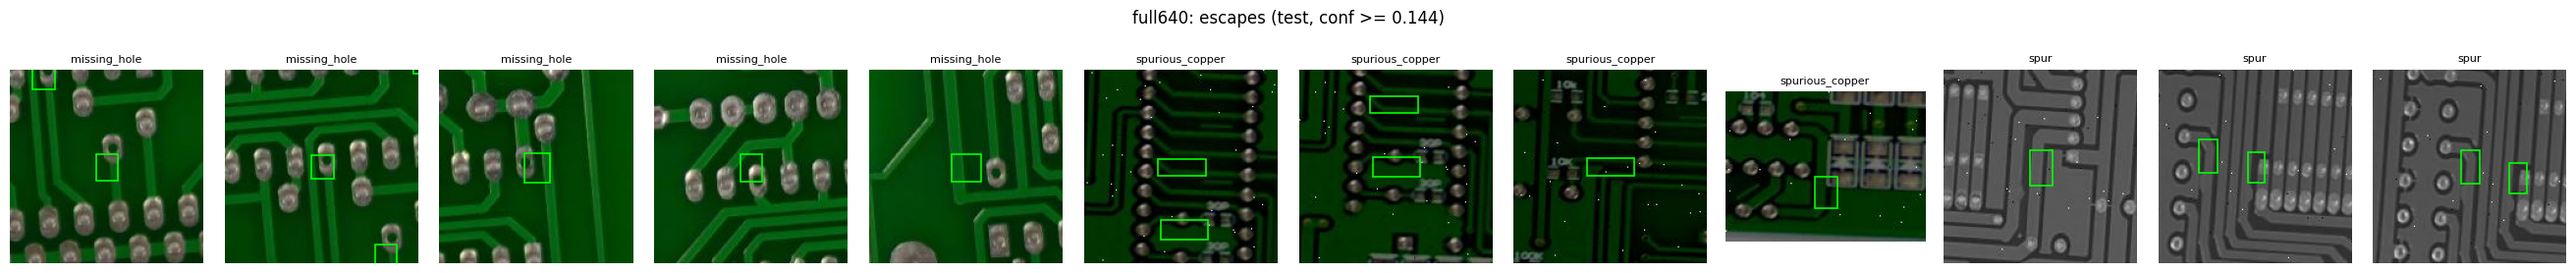

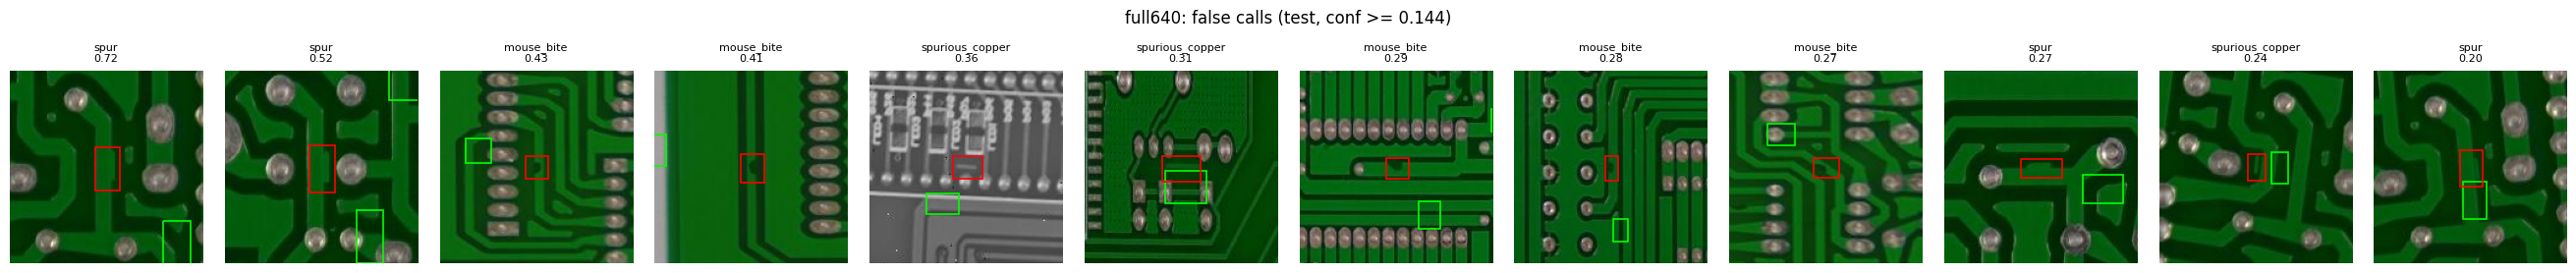

In [15]:
def crops(recs, preds, t, kind, n=12):
    items = []
    for r, d in zip(recs, preds):
        d = d.filter(d.scores >= t)
        M = box_iou(r["boxes"], d.boxes) >= cfg.match_iou
        if kind == "escape":
            for g in np.where(~M.any(1) if len(d) else np.ones(len(r["boxes"]), bool))[0]:
                items.append((r, r["boxes"][g], CLASSES[r["labels"][g]], 0.0))
        else:
            for k in (np.where(~M.any(0))[0] if len(d) else []):
                items.append((r, d.boxes[k], CLASSES[int(d.classes[k])], float(d.scores[k])))
    items = sorted(items, key=lambda x: -x[3])[:n]
    if not items:
        print(f"no {kind}s at this threshold"); return
    fig, axes = plt.subplots(1, len(items), figsize=(2.2 * len(items), 2.6), squeeze=False)
    for a, (r, b, c, s) in zip(axes[0], items):
        img = read_image(r["path"])[..., ::-1]; cx, cy = int((b[0] + b[2]) / 2), int((b[1] + b[3]) / 2); S = 80
        x0, y0 = max(cx - S, 0), max(cy - S, 0)
        a.imshow(img[y0:cy + S, x0:cx + S])
        for g in r["boxes"]:
            a.add_patch(plt.Rectangle((g[0] - x0, g[1] - y0), g[2] - g[0], g[3] - g[1], fill=False, ec="lime", lw=1.2))
        if kind != "escape":
            a.add_patch(plt.Rectangle((b[0] - x0, b[1] - y0), b[2] - b[0], b[3] - b[1], fill=False, ec="red", lw=1.2))
        a.set_title(f"{c}" + (f"\n{s:.2f}" if s else ""), fontsize=8); a.axis("off")
    fig.suptitle(f"{BEST}: {kind}s (test, conf >= {t:.3f})", y=1.05); plt.tight_layout()
    fig.savefig(cfg.out_dir / "figures" / f"{kind}s_{BEST}.png", dpi=150, bbox_inches="tight"); plt.show()

crops(SPLITS["test"], tp_best, OPS[BEST], "escape")
crops(SPLITS["test"], tp_best, OPS[BEST], "false call")

In [16]:
import onnx, onnxslim

DEPLOY = cfg.out_dir / "deploy" / "pcb"; DEPLOY.mkdir(parents=True, exist_ok=True)
v_best = cfg.variants[BEST]; S = v_best["imgsz"]

def export_fp32(weights, size, dst):
    y = YOLO(str(weights))
    with contextlib.redirect_stdout(io.StringIO()):
        src = Path(y.export(format="onnx", imgsz=size, dynamic=True, simplify=True, device="cpu"))
    m = onnx.load(str(src))
    dims = m.graph.input[0].type.tensor_type.shape.dim
    for i in (2, 3):
        dims[i].ClearField("dim_param"); dims[i].dim_value = size
    od = m.graph.output[0].type.tensor_type.shape.dim
    od[-1].ClearField("dim_value"); od[-1].dim_param = "anchors"
    del m.graph.value_info[:]
    m = onnxslim.slim(m)
    onnx.save(m, str(dst))
    return dst, len(y.model.model) - 1          # index of the Detect head (for INT8 exclusion)

fp32_path, head_idx = export_fp32(WEIGHTS[BEST], S, DEPLOY / "model_fp32.onnx")
print("fp32:", fp32_path, f"{fp32_path.stat().st_size / 2**20:.1f} MB | Detect head = model.{head_idx}")

def calibration_blob(n):
    rng = np.random.default_rng(cfg.seed)
    out = []
    recs = [SPLITS["train"][i] for i in rng.permutation(len(SPLITS["train"]))]
    for r in recs:
        img = read_image(r["path"])
        if v_best["mode"] == "tiled":
            tiles, origins = make_tiles(img, cfg.tile, cfg.overlap)
            has = [len(tile_boxes(r["boxes"], r["labels"], int(x), int(y), cfg.tile)[1]) > 0 for x, y in origins]
            pos = [i for i, h in enumerate(has) if h]; neg = [i for i, h in enumerate(has) if not h]
            pick = pos[:2] + list(rng.choice(neg, min(2, len(neg)), replace=False)) if neg else pos[:4]
            out.extend(tiles[pick])
        else:
            out.append(pcb_core.letterbox(img, S)[0])
        if len(out) >= n:
            break
    return to_blob(np.stack(out[:n]))

if HAS_MODELOPT:
    from modelopt.onnx.autocast import convert_to_mixed_precision
    from modelopt.onnx.quantization import quantize
    eps = ["cuda:0", "cpu"] if HAS_ORT_CUDA else ["cpu"]
    with contextlib.redirect_stdout(io.StringIO()):
        f16 = convert_to_mixed_precision(str(fp32_path), low_precision_type="fp16", keep_io_types=True)
    onnx.save(f16, str(DEPLOY / "model_fp16.onnx"))
    calib = calibration_blob(cfg.calib_tiles)
    print(f"calibration set: {calib.shape} from {len(SPLITS['train'])} training boards")
    excl = [rf"/model\.{head_idx}/.*"] if cfg.int8_keep_head_fp16 else None
    t0 = time.perf_counter()
    try:
        quantize(str(fp32_path), quantize_mode="int8", calibration_data={"images": calib}, calibration_method="entropy",
                 calibration_eps=eps, nodes_to_exclude=excl, high_precision_dtype="fp16",
                 output_path=str(DEPLOY / "model_int8.onnx"), log_level="WARNING")
    except Exception as e:          # e.g. CUDA EP not usable for calibration -> CPU
        print(f"calibration on {eps} failed ({type(e).__name__}); retrying on CPU")
        quantize(str(fp32_path), quantize_mode="int8", calibration_data={"images": calib}, calibration_method="entropy",
                 calibration_eps=["cpu"], nodes_to_exclude=excl, high_precision_dtype="fp16",
                 output_path=str(DEPLOY / "model_int8.onnx"), log_level="WARNING")
    del calib
    print(f"INT8 PTQ done in {time.perf_counter() - t0:.0f}s")
    q = onnx.load(str(DEPLOY / "model_int8.onnx"))
    ops = Counter(n.op_type for n in q.graph.node)
    print(f"INT8 graph: {ops['QuantizeLinear']} Q / {ops['DequantizeLinear']} DQ nodes, {ops['Conv']} Conv")
else:
    print("ModelOpt not installed: only the fp32 ONNX was exported (pip install \"nvidia-modelopt[onnx]\")")

# ---- deployment metadata used by the API
best_row = res_df.loc[BEST]
meta = {"model_name": f"{Path(cfg.model).stem}-{BEST}", "classes": CLASSES, "mode": v_best["mode"], "imgsz": S,
        "tile": cfg.tile, "overlap": cfg.overlap, "nms_iou": cfg.nms_iou, "merge_iou": cfg.merge_iou,
        "edge_margin": cfg.edge_margin, "max_tiles": MAX_TILES, "typical_tiles": TYPICAL_TILES,
        "typical_board_hw": list(TYPICAL_HW),
        "operating_point": {"conf_threshold": OPS[BEST], "false_call_budget_per_board": cfg.fcpb_target,
                            "chosen_on": "validation set", "match_iou": cfg.match_iou},
        "test_metrics": {k: round(float(best_row[k]), 4) for k in ["mAP50", "mAP50-95", "AP_small", "test_escape_pct",
                                                                   "test_false_calls_per_board"]},
        "created": time.strftime("%Y-%m-%d %H:%M:%S"), "ultralytics": ultralytics.__version__}
(DEPLOY / "meta.json").write_text(json.dumps(meta, indent=2))
sorted(p.name for p in DEPLOY.iterdir())

Ultralytics 8.4.191  Python-3.10.11 torch-2.14.1+cu126 CPU (Intel Core i5-8400 2.80GHz)
YOLO11s summary (fused): 100 layers, 9,415,122 parameters, 0 gradients, 21.4 GFLOPs

PyTorch: starting from 'C:\Users\RTX2080Ti\Desktop\ex\PCB_defect\pcb-aoi_3\artifacts\runs\full640\weights\best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 10, 8400) (18.3 MB)

ONNX: starting export with onnx 1.21.0 opset 18...
ONNX: slimming with onnxslim 0.1.98...
ONNX: export success  3.2s, saved as 'C:\Users\RTX2080Ti\Desktop\ex\PCB_defect\pcb-aoi_3\artifacts\runs\full640\weights\best.onnx' (36.5 MB)

Export complete (3.5s)
Results saved to C:\Users\RTX2080Ti\Desktop\ex\PCB_defect\pcb-aoi_3\artifacts\runs\full640\weights\best.onnx
Predict:         yolo predict task=detect model=C:\Users\RTX2080Ti\Desktop\ex\PCB_defect\pcb-aoi_3\artifacts\runs\full640\weights\best.onnx imgsz=640 
Validate:        yolo val task=detect model=C:\Users\RTX2080Ti\Desktop\ex\PCB_defect\pcb-aoi_3\artifacts\runs\ful

C:\Users\RTX2080Ti\AppData\Local\Programs\Python\Python310\lib\site-packages\cupy\_environment.py:677: UserWarning: 
--------------------------------------------------------------------------------

  CuPy may not function correctly because multiple CuPy packages are installed
  in your environment:

    cupy-cuda12x, cupy-cuda13x

  Follow these steps to resolve this issue:

    1. For all packages listed above, run the following command to remove all
       existing CuPy installations:

         $ pip uninstall <package_name>

      If you previously installed CuPy via conda, also run the following:

         $ conda uninstall cupy

    2. Install the appropriate CuPy package.
       Refer to the Installation Guide for detailed instructions.

         https://docs.cupy.dev/en/stable/install.html

--------------------------------------------------------------------------------

  warnings.warn(f'''


2026-10-29 15:08:44,996 - [modelopt][onnx] - WARNING - Shared constants were detected and duplicated accordingly.
2026-10-29 15:08:45,240 - [modelopt][onnx] - INFO - Successfully enabled 1 EPs for ORT: ['CPUExecutionProvider']
2026-10-29 15:08:45,495 - [modelopt][onnx] - INFO - Running ONNX Runtime to obtain reference outputs (this may take a while)...
2026-10-29 15:08:46,907 - [modelopt][onnx] - INFO - Skipping node /model.23/Mul_5: reference IO out of range: min=2.917773485183716, max=637.048828125, absmax=637.048828125, range=[-512, 512]
2026-10-29 15:08:46,907 - [modelopt][onnx] - INFO - Skipping node /model.23/Concat_26: reference IO out of range: min=2.917773485183716, max=637.048828125, absmax=637.048828125, range=[-512, 512]
2026-10-29 15:08:47,004 - [modelopt][onnx] - WARNING - Did not find  in value info map! Assuming not castable
2026-10-29 15:08:47,104 - [modelopt][onnx] - WARNING - Some initializers contain values smaller than smallest fp16 value, values will be replaced w

100%|██████████| 158/158 [00:00<00:00, 175.13it/s]


100%|██████████| 158/158 [00:00<00:00, 199.80it/s]


...

100%|██████████| 158/158 [00:00<00:00, 198.27it/s]


100%|██████████| 158/158 [00:00<00:00, 198.28it/s]


100%|██████████| 158/158 [00:00<00:00, 202.24it/s]


Finding optimal threshold for each tensor using 'entropy' algorithm ...
Number of tensors : 158
Number of histogram bins : 128 (The number may increase depends on the data it collects)
Number of quantized bins : 128
2026-10-29 15:13:28,964 - [modelopt][onnx] - WARNING - Found QuantizeLinear/DequantizeLinear nodes. Updating minimum opset from 13 to 19.
2026-10-29 15:13:28,979 - [modelopt][onnx] - WARNING - Shared constants were detected and duplicated accordingly.
2026-10-29 15:13:29,114 - [modelopt][onnx] - WARNING - Did not find  in value info map! Assuming not castable
2026-10-29 15:13:29,271 - [modelopt][onnx] - WARNING - Some initializers contain values smaller than smallest fp16 value, values will be replaced with 6.0e-08.
INT8 PTQ done in 283s
INT8 graph: 144 Q / 144 DQ nodes, 88 Conv


['meta.json', 'model_fp16.onnx', 'model_fp32.onnx', 'model_int8.onnx']

In [17]:
# Parity on training tiles: compare the DETECTIONS each ONNX model produces with PyTorch fp32's (conf >= 0.25)
if ort is not None:
    x = calibration_blob(16)
    ref_dets = pcb_core.decode(TorchRunner(WEIGHTS[BEST])(x), 0.25)
    prov = ["CUDAExecutionProvider", "CPUExecutionProvider"] if HAS_ORT_CUDA else ["CPUExecutionProvider"]
    rows = []
    for prec in ("fp32", "fp16", "int8"):
        p = DEPLOY / f"model_{prec}.onnx"
        if not p.exists():
            continue
        try:
            y = ort.InferenceSession(str(p), providers=prov).run(None, {"images": x})[0]
        except Exception as e:
            rows.append({"precision": prec, "note": f"ORT could not run it here ({type(e).__name__})"}); continue
        dets = pcb_core.decode(y, 0.25)
        ious, n_ref, n_new, dconf = [], 0, 0, []
        for a, b in zip(ref_dets, dets):
            n_ref += len(a); n_new += len(b)
            if len(a) and len(b):
                M = box_iou(a.boxes, b.boxes); j = M.argmax(1); ok = M.max(1) > 0.5
                ious.extend(M.max(1)[ok]); dconf.extend(np.abs(a.scores[ok] - b.scores[j[ok]]))
        rows.append({"precision": prec, "size_MB": round(p.stat().st_size / 2**20, 1),
                     "detections (PyTorch fp32 / this model)": f"{n_ref} / {n_new}",
                     "matched IoU (mean)": float(np.mean(ious)) if ious else float("nan"),
                     "|confidence diff| (mean)": float(np.mean(dconf)) if dconf else float("nan")})
    display(pd.DataFrame(rows))

,precision,size_MB,detections (PyTorch fp32 / this model),matched IoU (mean),|confidence diff| (mean)
0,fp32,36.1,0 / 0,NaN,NaN
1,fp16,18.2,0 / 0,NaN,NaN
2,int8,18.4,0 / 0,NaN,NaN


In [18]:
BUILD_SCRIPT = PROJECT_ROOT / "serve" / "app" / "build_trt_engine.py"
ENGINES = {}
if HAS_TRT:
    max_b = MAX_TILES if v_best["mode"] == "tiled" else 1
    opt_b = TYPICAL_TILES if v_best["mode"] == "tiled" else 1
    for prec in ("fp32", "fp16", "int8"):
        onnx_path = DEPLOY / f"model_{prec}.onnx"
        if not onnx_path.exists():
            continue
        engine = cfg.out_dir / "engines" / f"{BEST}_{prec}_b{max_b}_trt{trt.__version__}.engine"
        if not engine.exists():
            cmd = [sys.executable, str(BUILD_SCRIPT), "--onnx", str(onnx_path), "--engine", str(engine),
                   "--max-batch", str(max_b), "--opt-batch", str(opt_b)]
            r = subprocess.run(cmd, capture_output=True, text=True, env=os.environ.copy())
            print(r.stdout.strip())
            if r.returncode != 0:
                print(r.stderr[-5000:])
                print(f"!! {prec} engine failed (exit {r.returncode & 0xFFFFFFFF:#x}); "
                      f"debug with: {' '.join(cmd)} --verbose")
                continue
        ENGINES[prec] = engine
else:
    print("TensorRT not available: skipping")
ENGINES

[build] python 3.10.11 | CUDA_VISIBLE_DEVICES=1
[build] TensorRT 11.4.0.106
[build] parsing C:\Users\RTX2080Ti\Desktop\ex\PCB_defect\pcb-aoi_3\artifacts\deploy\pcb\model_fp16.onnx
[build] building images (-1, 3, 640, 640) batch 1..1 (opt 1) ...
[build] OK in 148s -> C:\Users\RTX2080Ti\Desktop\ex\PCB_defect\pcb-aoi_3\artifacts\engines\full640_fp16_b1_trt11.4.0.106.engine (94.9 MB) | io: ['images:DataType.FLOAT', 'output0:DataType.FLOAT']
[build] python 3.10.11 | CUDA_VISIBLE_DEVICES=1
[build] TensorRT 11.4.0.106
[build] parsing C:\Users\RTX2080Ti\Desktop\ex\PCB_defect\pcb-aoi_3\artifacts\deploy\pcb\model_int8.onnx
[build] building images (-1, 3, 640, 640) batch 1..1 (opt 1) ...
[build] OK in 127s -> C:\Users\RTX2080Ti\Desktop\ex\PCB_defect\pcb-aoi_3\artifacts\engines\full640_int8_b1_trt11.4.0.106.engine (59.0 MB) | io: ['images:DataType.FLOAT', 'output0:DataType.FLOAT']


{'fp32': WindowsPath('C:/Users/RTX2080Ti/Desktop/ex/PCB_defect/pcb-aoi_3/artifacts/engines/full640_fp32_b1_trt11.4.0.106.engine'),
 'fp16': WindowsPath('C:/Users/RTX2080Ti/Desktop/ex/PCB_defect/pcb-aoi_3/artifacts/engines/full640_fp16_b1_trt11.4.0.106.engine'),
 'int8': WindowsPath('C:/Users/RTX2080Ti/Desktop/ex/PCB_defect/pcb-aoi_3/artifacts/engines/full640_int8_b1_trt11.4.0.106.engine')}

In [19]:
class TRTRunner:
    # TensorRT engine as a pcb_core RunFn, using PyTorch tensors as device buffers.
    TO_TORCH = {}
    def __init__(self, path):
        if not TRTRunner.TO_TORCH:
            TRTRunner.TO_TORCH = {trt.DataType.FLOAT: torch.float32, trt.DataType.HALF: torch.float16}
        self.engine = trt.Runtime(trt.Logger(trt.Logger.WARNING)).deserialize_cuda_engine(Path(path).read_bytes())
        self.ctx = self.engine.create_execution_context()
        names = [self.engine.get_tensor_name(i) for i in range(self.engine.num_io_tensors)]
        self.inp = next(n for n in names if self.engine.get_tensor_mode(n) == trt.TensorIOMode.INPUT)
        self.out = next(n for n in names if n != self.inp)
        self.max_b = int(self.engine.get_tensor_profile_shape(self.inp, 0)[2][0])
        self.in_dt = TRTRunner.TO_TORCH[self.engine.get_tensor_dtype(self.inp)]
        self.out_dt = TRTRunner.TO_TORCH[self.engine.get_tensor_dtype(self.out)]
        self._bufs = {}
    def _run(self, blob):
        x = torch.from_numpy(blob).to(DEVICE).to(self.in_dt).contiguous()
        shape = tuple(x.shape)
        self.ctx.set_input_shape(self.inp, shape)
        if shape not in self._bufs:
            self._bufs[shape] = torch.empty(tuple(self.ctx.get_tensor_shape(self.out)), dtype=self.out_dt, device=DEVICE)
        y = self._bufs[shape]
        self.ctx.set_tensor_address(self.inp, x.data_ptr()); self.ctx.set_tensor_address(self.out, y.data_ptr())
        if not self.ctx.execute_async_v3(torch.cuda.current_stream().cuda_stream):
            raise RuntimeError("TensorRT execution failed")
        return y.float().cpu().numpy()
    def __call__(self, blob):
        return np.concatenate([self._run(blob[i:i + self.max_b]) for i in range(0, len(blob), self.max_b)])

class ORTRunner:
    def __init__(self, path, providers):
        self.sess = ort.InferenceSession(str(path), providers=providers)
    def __call__(self, blob):
        return self.sess.run(None, {"images": blob})[0]

backends = {"PyTorch fp32": lambda: TorchRunner(WEIGHTS[BEST]), "PyTorch fp16": lambda: TorchRunner(WEIGHTS[BEST], half=True)}
if HAS_ORT_CUDA:
    backends["ORT-CUDA fp32"] = lambda: ORTRunner(DEPLOY / "model_fp32.onnx", ["CUDAExecutionProvider"])
for prec, path in ENGINES.items():
    backends[f"TensorRT {prec}"] = (lambda p=path: TRTRunner(p))
if DEVICE.type != "cuda" and ort is not None:          # CPU-only machine: still compare the ONNX variants
    for prec in ("fp32", "int8"):
        if (DEPLOY / f"model_{prec}.onnx").exists():
            backends[f"ORT-CPU {prec}"] = (lambda p=DEPLOY / f"model_{prec}.onnx": ORTRunner(p, ["CPUExecutionProvider"]))

t_op = OPS[BEST]
bench_recs = SPLITS["test"][:cfg.bench_boards]
rows = []
for name, make in backends.items():
    try:
        run = make()
        preds, _ = infer_boards(run, SPLITS["test"], v_best, cfg.eval_conf, progress=f"{name} accuracy")
        overall, _ = coco_eval(SPLITS["test"], preds)
        op = at_threshold(*aoi_scores(SPLITS["test"], preds, cfg.match_iou), t_op)
        infer_boards(run, bench_recs[:cfg.bench_warmup], v_best, t_op)                       # warm-up
        _, times = infer_boards(run, bench_recs, v_best, t_op, progress=f"{name} timing")
    except Exception as e:
        print(f"{name}: failed ({type(e).__name__}: {e})"); continue
    board = np.array([t["board_ms"] for t in times]); inf = np.array([t.get("inference_ms", np.nan) for t in times])
    rows.append({"backend": name, "mAP50": 100 * overall["mAP50"], "mAP50-95": 100 * overall["mAP50-95"],
                 "escape_pct@op": 100 * op["escape_rate"], "false_calls/board@op": op["false_calls_per_board"],
                 "inference_ms/board p50": np.nanpercentile(inf, 50) if v_best["mode"] == "tiled" else np.nan,
                 "board_ms p50": np.percentile(board, 50), "board_ms p95": np.percentile(board, 95),
                 "boards/hour": 3600e3 / np.percentile(board, 50)})
    print(f"{name:<15} mAP50 {rows[-1]['mAP50']:.1f} | escape {rows[-1]['escape_pct@op']:.2f}% | "
          f"board p50 {rows[-1]['board_ms p50']:.1f} ms")
    del run
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

bench_df = pd.DataFrame(rows).set_index("backend")
bench_df.to_csv(cfg.out_dir / "results" / "backend_benchmark.csv")
env = {"gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "cpu", "torch": torch.__version__,
       "ultralytics": ultralytics.__version__, "onnxruntime": getattr(ort, "__version__", None),
       "tensorrt": getattr(trt, "__version__", None), "variant": BEST, "boards_timed": len(bench_recs),
       "operating_conf": t_op}
(cfg.out_dir / "results" / "benchmark_env.json").write_text(json.dumps(env, indent=2))
bench_df.round(2)

PyTorch fp32 accuracy:   0%|          | 0/104 [00:00<?, ?it/s]

PyTorch fp32 timing:   0%|          | 0/60 [00:00<?, ?it/s]

PyTorch fp32    mAP50 5.6 | escape 96.58% | board p50 17.2 ms


PyTorch fp16 accuracy:   0%|          | 0/104 [00:00<?, ?it/s]

PyTorch fp16 timing:   0%|          | 0/60 [00:00<?, ?it/s]

...

TensorRT fp16   mAP50 5.5 | escape 96.35% | board p50 14.3 ms


TensorRT int8 accuracy:   0%|          | 0/104 [00:00<?, ?it/s]

TensorRT int8 timing:   0%|          | 0/60 [00:00<?, ?it/s]

TensorRT int8   mAP50 5.4 | escape 97.95% | board p50 14.4 ms


,mAP50,mAP50-95,escape_pct@op,false_calls/board@op,inference_ms/board p50,board_ms p50,board_ms p95,boards/hour
backend,,,,,,,,
PyTorch fp32,5.58,1.65,96.58,0.29,NaN,17.16,21.40,209829.95
PyTorch fp16,5.54,1.64,96.35,0.28,NaN,18.19,23.49,197931.61
ORT-CUDA fp32,5.58,1.65,96.58,0.29,NaN,13.68,15.05,263100.20
TensorRT fp32,5.58,1.65,96.58,0.29,NaN,13.57,15.24,265283.26
TensorRT fp16,5.53,1.63,96.35,0.28,NaN,14.32,16.47,251390.50
TensorRT int8,5.36,1.66,97.95,0.20,NaN,14.37,16.45,250501.87


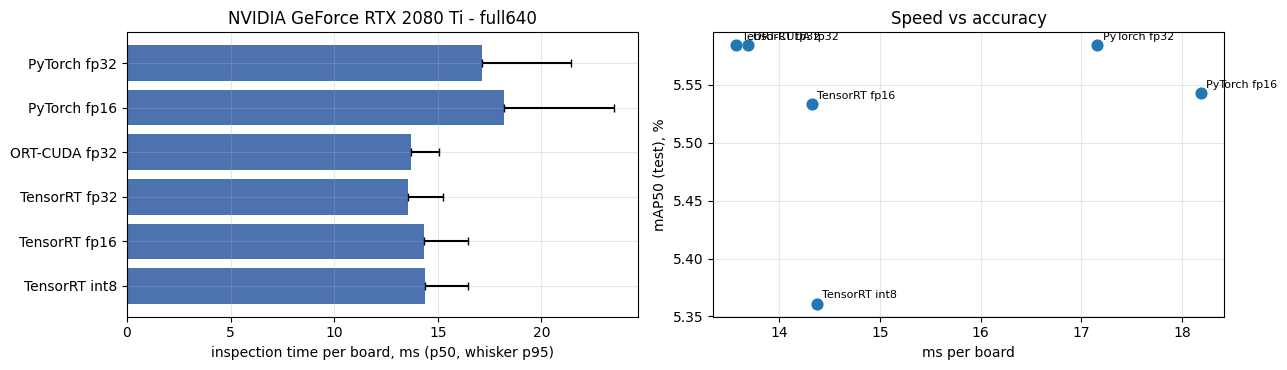

In [20]:
if len(bench_df):
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
    axes[0].barh(bench_df.index, bench_df["board_ms p50"], color="#4C72B0",
                 xerr=[np.zeros(len(bench_df)), bench_df["board_ms p95"] - bench_df["board_ms p50"]], capsize=3)
    axes[0].invert_yaxis(); axes[0].set_xlabel("inspection time per board, ms (p50, whisker p95)")
    axes[0].set_title(f"{env['gpu']} - {BEST}")
    axes[1].scatter(bench_df["board_ms p50"], bench_df["mAP50"], s=60)
    for n, r in bench_df.iterrows():
        axes[1].annotate(n, (r["board_ms p50"], r["mAP50"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
    axes[1].set_xlabel("ms per board"); axes[1].set_ylabel("mAP50 (test), %"); axes[1].set_title("Speed vs accuracy")
    for a in axes: a.grid(alpha=0.3)
    plt.tight_layout(); fig.savefig(cfg.out_dir / "figures" / "backend_benchmark.png", dpi=150); plt.show()

In [22]:
import requests, base64
API_URL = os.environ.get("API_URL", "http://127.0.0.1:8000")
try:
    health = requests.get(f"{API_URL}/health", timeout=3).json(); API_UP = True
    print(json.dumps(health, indent=2)); print(json.dumps(requests.get(f"{API_URL}/model", timeout=3).json(), indent=2))
except requests.RequestException as e:
    API_UP = False; print(f"API not reachable at {API_URL} ({type(e).__name__}); start it and re-run.")

{
  "status": "ok",
  "backend": "trt",
  "precision": "int8",
  "runtime": "tensorrt-11.4.0.106",
  "model": "yolo11s-full640"
}
{
  "model_name": "yolo11s-full640",
  "classes": [
    "missing_hole",
    "mouse_bite",
    "open_circuit",
    "short",
    "spur",
    "spurious_copper"
  ],
  "mode": "full",
  "tile": 640,
  "overlap": 0.25,
  "imgsz": 640,
  "operating_point": {
    "conf_threshold": 0.14355254173278809,
    "false_call_budget_per_board": 0.2,
    "chosen_on": "validation set",
    "match_iou": 0.25
  },
  "test_metrics": {
    "mAP50": 5.5843,
    "mAP50-95": 1.6458,
    "AP_small": 1.6732,
    "test_escape_pct": 96.5753,
    "test_false_calls_per_board": 0.2885
  },
  "conf_threshold_in_use": 0.14355254173278809
}


API: PASS, 0 defects | notebook PyTorch fp32: 0 | ground truth: 5
matched API<->notebook boxes (IoU>0.5): 0 | timings: {'decode_ms': 2.11, 'inference_ms': 38.76, 'total_ms': 44.12}


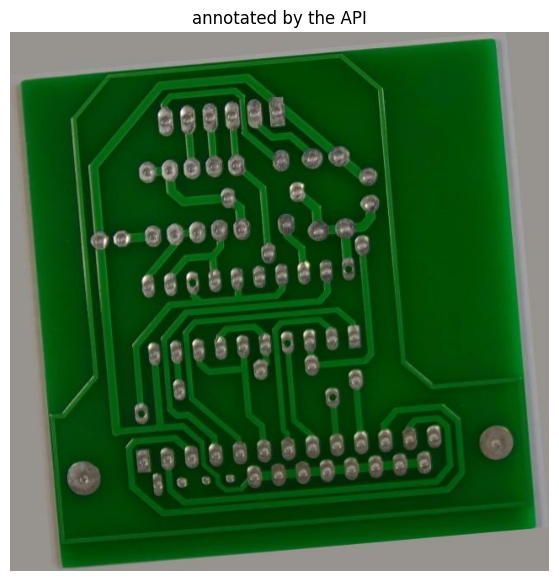

In [23]:
if API_UP:
    r0 = SPLITS["test"][0]
    resp = requests.post(f"{API_URL}/inspect", files={"file": (r0["path"].name, r0["path"].read_bytes(), "image/jpeg")},
                         params={"return_image": "true"}, timeout=60).json()
    api_det = Detections(np.array([d["box"] for d in resp["defects"]], np.float32).reshape(-1, 4),
                         np.array([d["confidence"] for d in resp["defects"]], np.float32),
                         np.array([d["class_id"] for d in resp["defects"]], np.int64))
    ref = infer_boards(TorchRunner(WEIGHTS[BEST]), [r0], v_best, resp["conf_threshold"])[0][0]
    M = box_iou(api_det.boxes, ref.boxes)
    print(f"API: {resp['verdict']}, {resp['num_defects']} defects | notebook PyTorch fp32: {len(ref)} | ground truth: {len(r0['boxes'])}")
    print("matched API<->notebook boxes (IoU>0.5):", int((M.max(1) > 0.5).sum()) if M.size else 0, "| timings:", resp["timing_ms"])
    img = cv2.imdecode(np.frombuffer(base64.b64decode(resp["annotated_jpeg_base64"]), np.uint8), cv2.IMREAD_COLOR)
    plt.figure(figsize=(12, 7)); plt.imshow(img[..., ::-1]); plt.axis("off"); plt.title("annotated by the API"); plt.show()
else:
    print("skipped")

In [24]:
from concurrent.futures import ThreadPoolExecutor
def load_test(concurrency, n):
    payloads = [(r["path"].name, r["path"].read_bytes()) for r in SPLITS["test"][:20]]
    def one(i):
        name, data = payloads[i % len(payloads)]
        t0 = time.perf_counter()
        requests.post(f"{API_URL}/inspect", files={"file": (name, data, "image/jpeg")}, timeout=120).raise_for_status()
        return (time.perf_counter() - t0) * 1e3
    one(0)
    t0 = time.perf_counter()
    with ThreadPoolExecutor(concurrency) as ex:
        lat = np.array(list(ex.map(one, range(n))))
    wall = time.perf_counter() - t0
    return {"concurrency": concurrency, "boards_per_s": n / wall, "boards_per_hour": 3600 * n / wall,
            "p50_ms": np.percentile(lat, 50), "p95_ms": np.percentile(lat, 95)}

if API_UP:
    lt = pd.DataFrame([load_test(c, 8 if QUICK else 60) for c in (1, 2, 4)])
    lt.to_csv(cfg.out_dir / "results" / "api_load_test.csv", index=False)
    display(lt.round(1))
else:
    print("skipped")

,concurrency,boards_per_s,boards_per_hour,p50_ms,p95_ms
0,1,21.4,77049.4,47.4,51.3
1,2,61.4,220921.1,32.1,48.4
2,4,117.4,422778.9,33.2,47.7
